Full months: 24 | from 2009-12-01 to 2011-11-01
Total gross sales: £18,750,628


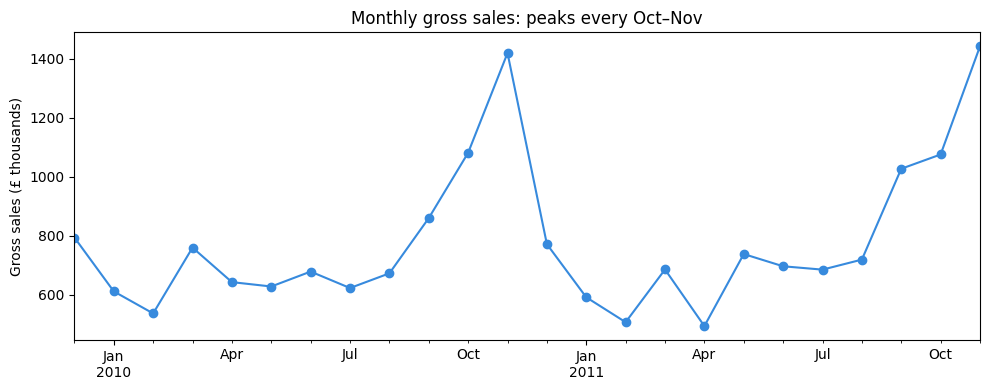

In [1]:
# Step 1: Load monthly sales and plot the full months
import pandas as pd
import matplotlib.pyplot as plt

m = pd.read_csv("monthly_sales.csv", parse_dates=["month"])

# Drop Dec 2011: it has only 9 days of data (see project brief)
m = m[m["is_partial_month"].astype(str).str.lower() != "true"].sort_values("month")
sales = m.set_index("month")["gross_sales_gbp"].astype(float)

print("Full months:", len(sales), "| from", sales.index.min().date(), "to", sales.index.max().date())
print("Total gross sales: £{:,.0f}".format(sales.sum()))

ax = (sales / 1000).plot(figsize=(10, 4), marker="o", color="#378ADD")
ax.set_title("Monthly gross sales: peaks every Oct–Nov")
ax.set_ylabel("Gross sales (£ thousands)")
ax.set_xlabel("")
plt.tight_layout()
plt.show()

Recent growth factor (Mar-May 2011 vs Mar-May 2010): 0.944

                                       Avg monthly error (MAPE %)  \
Seasonal naive (same month last year)                         6.1   
Seasonal naive + recent growth                               11.1   
Naive (repeat last month)                                    20.8   

                                       6-month total error (%)  
Seasonal naive (same month last year)                     -5.5  
Seasonal naive + recent growth                           -10.8  
Naive (repeat last month)                                -21.6  


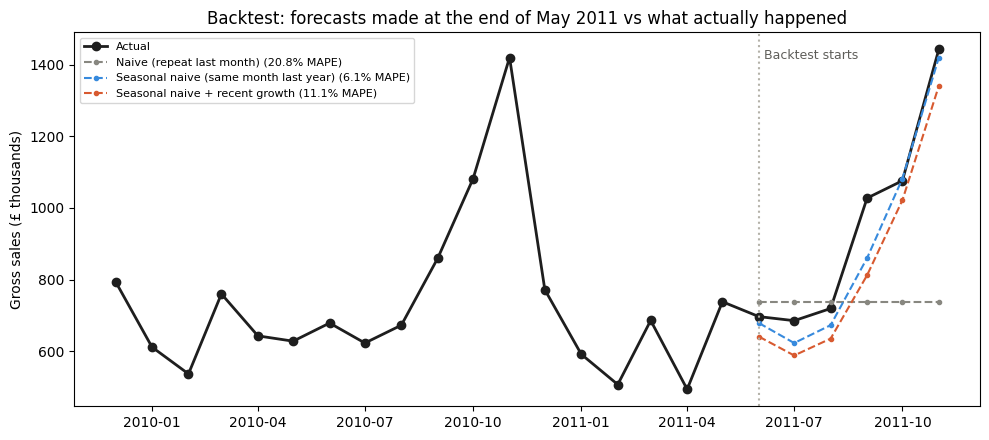

In [2]:
# Step 2: Backtest - pretend it's the end of May 2011, forecast Jun-Nov 2011, compare with reality
train = sales[:"2011-05-01"]
test = sales["2011-06-01":"2011-11-01"]

def same_month_last_year(index):
    return sales.reindex(index - pd.DateOffset(years=1)).values

forecasts = pd.DataFrame(index=test.index)
forecasts["Naive (repeat last month)"] = train.iloc[-1]
forecasts["Seasonal naive (same month last year)"] = same_month_last_year(test.index)

growth = train["2011-03-01":"2011-05-01"].sum() / sales["2010-03-01":"2010-05-01"].sum()
forecasts["Seasonal naive + recent growth"] = same_month_last_year(test.index) * growth
print("Recent growth factor (Mar-May 2011 vs Mar-May 2010): {:.3f}\n".format(growth))

def mape(f):
    return (abs(test - f) / test).mean() * 100

def total_error(f):
    return (f.sum() - test.sum()) / test.sum() * 100

scores = pd.DataFrame({
    "Avg monthly error (MAPE %)": forecasts.apply(mape).round(1),
    "6-month total error (%)": forecasts.apply(total_error).round(1),
}).sort_values("Avg monthly error (MAPE %)")
print(scores)

# Chart: actual sales vs each method's forecast
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(sales.index, sales / 1000, marker="o", color="#1E1E1E", label="Actual", linewidth=2)
colors = {"Naive (repeat last month)": "#888780",
          "Seasonal naive (same month last year)": "#378ADD",
          "Seasonal naive + recent growth": "#D85A30"}
for name in forecasts.columns:
    ax.plot(forecasts.index, forecasts[name] / 1000, linestyle="--", marker=".",
            color=colors[name], label=f"{name} ({scores.loc[name].iloc[0]}% MAPE)")
ax.axvline(pd.Timestamp("2011-06-01"), color="#B4B2A9", linestyle=":")
ax.text(pd.Timestamp("2011-06-05"), ax.get_ylim()[1] * 0.95, "Backtest starts", color="#5F5E5A", fontsize=9)
ax.set_title("Backtest: forecasts made at the end of May 2011 vs what actually happened")
ax.set_ylabel("Gross sales (£ thousands)")
ax.legend(fontsize=8, loc="upper left")
plt.tight_layout()
plt.savefig("forecast_backtest.png", dpi=150)
plt.show()

          Forecast (£)   Low (£)  High (£)
Dec 2011      771935.0  724847.0  819023.0
Jan 2012      591911.0  555804.0  628017.0
Feb 2012      507508.0  476550.0  538466.0

Next-quarter total: £1,871,354  (range £1,757,201 to £1,985,506)
Note: in the backtest this method under-forecast by 5.5%, so actual sales may land toward the high end.


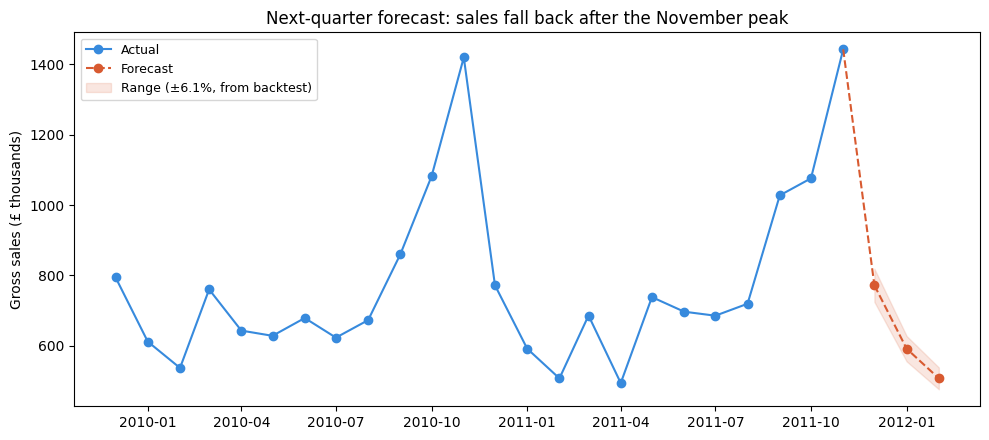

Saved: forecast_backtest.png, forecast_next_quarter.png, revenue_forecast.csv


In [3]:
# Step 3: Forecast the next quarter (Dec 2011 - Feb 2012) with the winning method
best = "Seasonal naive (same month last year)"
err = scores.loc[best, "Avg monthly error (MAPE %)"] / 100   # backtest error, used as the range

future = pd.date_range("2011-12-01", periods=3, freq="MS")
fc = pd.Series(sales.reindex(future - pd.DateOffset(years=1)).values, index=future)

table = pd.DataFrame({
    "Forecast (£)": fc,
    "Low (£)": fc * (1 - err),
    "High (£)": fc * (1 + err),
}).round(0)
table.index = table.index.strftime("%b %Y")
print(table.to_string())
print("\nNext-quarter total: £{:,.0f}  (range £{:,.0f} to £{:,.0f})".format(
    fc.sum(), fc.sum() * (1 - err), fc.sum() * (1 + err)))
print("Note: in the backtest this method under-forecast by 5.5%, so actual sales may land toward the high end.")

# Chart: history + forecast with its range
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(sales.index, sales / 1000, marker="o", color="#378ADD", label="Actual")
ax.plot(fc.index, fc / 1000, marker="o", linestyle="--", color="#D85A30", label="Forecast")
ax.fill_between(fc.index, fc * (1 - err) / 1000, fc * (1 + err) / 1000,
                color="#D85A30", alpha=0.15, label=f"Range (±{err:.1%}, from backtest)")
ax.plot([sales.index[-1], fc.index[0]], [sales.iloc[-1] / 1000, fc.iloc[0] / 1000],
        linestyle="--", color="#D85A30")
ax.set_title("Next-quarter forecast: sales fall back after the November peak")
ax.set_ylabel("Gross sales (£ thousands)")
ax.legend(fontsize=9, loc="upper left")
plt.tight_layout()
plt.savefig("forecast_next_quarter.png", dpi=150)
plt.show()

# Save the forecast for GitHub (and Tableau, if you add it later)
table.to_csv("revenue_forecast.csv")
print("Saved: forecast_backtest.png, forecast_next_quarter.png, revenue_forecast.csv")